In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from google.colab import files

uploaded = files.upload()
file_name = next(iter(uploaded))

# Try reading the CSV with the Python parser
df = pd.read_csv(
    file_name,
    sep=",",
    engine="python",
    on_bad_lines="warn"
)

print("Dataset loaded successfully!")
print("File name:", file_name)
print("Dataset shape:", df.shape)

df.head()

Saving movie_dataset_pca.csv to movie_dataset_pca (2).csv
Dataset loaded successfully!
File name: movie_dataset_pca (2).csv
Dataset shape: (5043, 16)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,gross
0,1.092703,-0.405484,3.837326,0.116049,-0.595945,0.498601,0.134162,0.157632,-0.767187,0.084370,0.536613,0.348679,-0.175691,-0.439397,-0.864804,760505847.0
1,4.099777,-1.587068,1.062382,0.067204,-1.760890,1.842817,0.133070,0.667983,-0.326272,0.287283,-0.752192,0.545707,-0.120800,-0.538285,-0.656269,309404152.0
2,2.296529,0.831743,3.552764,-0.335591,0.061303,0.249403,-0.106573,0.269020,-0.244184,1.596260,2.628234,0.732858,0.047728,-0.351859,-0.132918,200074175.0
3,13.940466,-3.229470,2.800851,-2.565933,10.884766,-4.114651,-2.180997,2.299913,-1.369925,-0.906790,0.235065,-0.869056,-4.711812,0.407099,-0.777464,448130642.0
4,-1.300328,1.582147,-1.164683,-2.450296,0.617681,2.068219,0.016359,1.272260,-1.557879,-2.240776,0.952125,0.738833,-0.039699,0.239675,0.154189,NaN


# New Section

In [28]:
y = df['gross']

X = df.drop('gross', axis=1)

X = X.select_dtypes(include=np.number)

X = X.replace([np.inf, -np.inf], np.nan)

X = X.dropna(axis=1, how='all')

imputer = SimpleImputer(strategy='median')
X = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

X = X.loc[:, X.nunique() > 1]

print("Features Shape:", X.shape)

Features Shape: (5043, 15)


In [29]:
pca = PCA()

pca.fit(X)

explained_variance = pca.explained_variance_ratio_

cumulative_variance = np.cumsum(explained_variance)

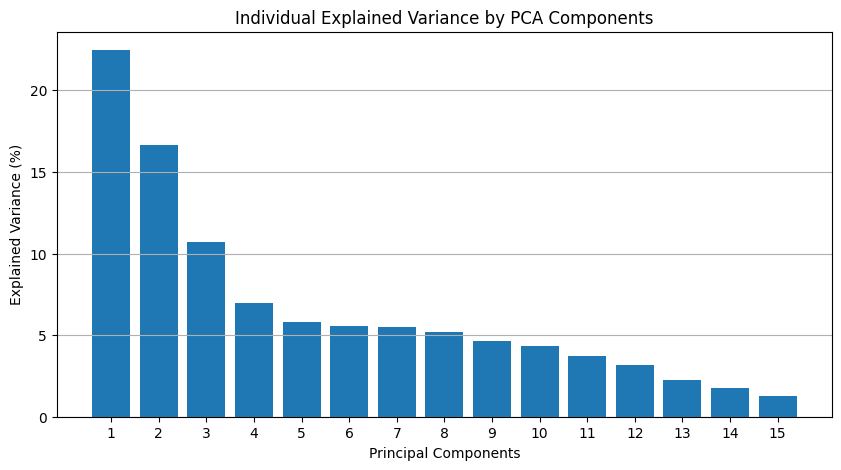

In [30]:
plt.figure(figsize=(10, 5))

plt.bar(range(1, len(explained_variance) + 1),
        explained_variance * 100)

plt.xlabel('Principal Components')
plt.ylabel('Explained Variance (%)')
plt.title('Individual Explained Variance by PCA Components')

plt.xticks(range(1, len(explained_variance) + 1))
plt.grid(axis='y')

plt.show()

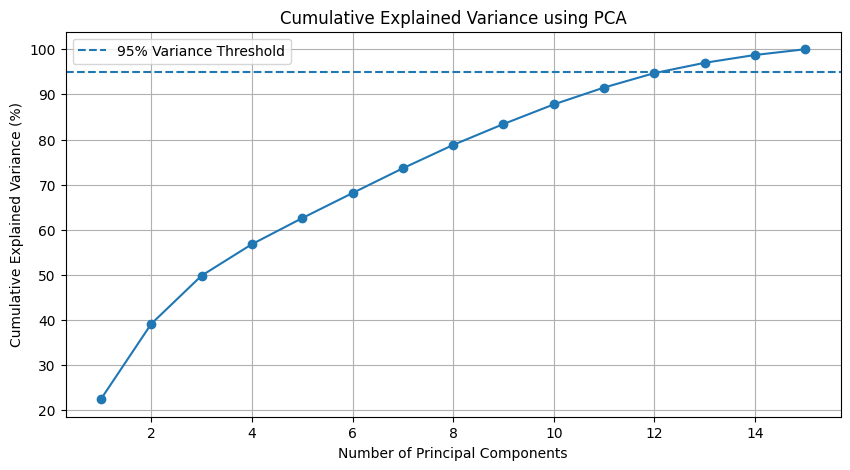

In [31]:
plt.figure(figsize=(10, 5))

plt.plot(range(1, len(cumulative_variance) + 1),
         cumulative_variance * 100,
         marker='o')

plt.axhline(y=95, linestyle='--', label='95% Variance Threshold')

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance (%)')
plt.title('Cumulative Explained Variance using PCA')

plt.legend()
plt.grid()

plt.show()

In [32]:
variance_table = pd.DataFrame({
    'Principal Component': [f'PC{i}' for i in range(1, len(explained_variance) + 1)],
    'Individual Variance (%)': explained_variance * 100,
    'Cumulative Variance (%)': cumulative_variance * 100
})

print(variance_table.round(2))

   Principal Component  Individual Variance (%)  Cumulative Variance (%)
0                  PC1                    22.47                    22.47
1                  PC2                    16.68                    39.15
2                  PC3                    10.69                    49.83
3                  PC4                     6.97                    56.80
4                  PC5                     5.78                    62.58
5                  PC6                     5.55                    68.14
6                  PC7                     5.49                    73.62
7                  PC8                     5.17                    78.80
8                  PC9                     4.63                    83.43
9                 PC10                     4.35                    87.78
10                PC11                     3.74                    91.52
11                PC12                     3.20                    94.71
12                PC13                     2.28    

In [33]:
n_components = np.argmax(cumulative_variance >= 0.95) + 1

print("Number of components required:", n_components)

print("Variance retained:",
      round(cumulative_variance[n_components - 1] * 100, 2), "%")

Number of components required: 13
Variance retained: 96.99 %
